# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [50]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Display more columns when inspecting the dataset
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)

## Exploratory Data Analysis  
- Load in the cleaned data

In [51]:
df = pd.read_csv("AviationData_clean.csv", low_memory=False)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (60236, 34)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Airport.Code,Airport.Name,Injury.Severity,Aircraft.damage,Aircraft.Category,Registration.Number,Make,Model,Amateur.Built,Number.of.Engines,Engine.Type,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Year,Total.Occupants,Severe.Injuries,Severe.Injury.Rate,Fatal.Rate,Any.Severe.Injury,Destroyed,Plane.ID
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,ONP,NEWPORT MUNICIPAL,Non-Fatal,Substantial,Airplane,N1296M,CESSNA,182P,No,1.0,Reciprocating,Personal,0.0,0.0,1.0,3.0,VMC,Approach,Probable Cause,NaN,1983,4.0,0.0,0.0,0.0,0,0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,3YR,MUNICIPAL,Non-Fatal,Substantial,Airplane,N2639C,CESSNA,182RG,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN,1983,2.0,0.0,0.0,0.0,0,0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,78Y,RANKIN,Non-Fatal,Substantial,Airplane,N58664,CESSNA,182P,No,1.0,Reciprocating,Personal,0.0,0.0,0.0,1.0,VMC,Takeoff,Probable Cause,NaN,1983,1.0,0.0,0.0,0.0,0,0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,CCB,CABLE,Non-Fatal,Substantial,Airplane,N3084R,PIPER,PA-28R-200,No,1.0,Reciprocating,Personal,0.0,0.0,2.0,0.0,VMC,Approach,Probable Cause,NaN,1983,2.0,0.0,0.0,0.0,0,0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,OFF-AIRPORT,SPRINGBROOK,Non-Fatal,Substantial,Airplane,N89399,CESSNA,140,No,1.0,Reciprocating,Instructional,0.0,0.0,0.0,2.0,VMC,Landing,Probable Cause,NaN,1983,2.0,0.0,0.0,0.0,0,0,CESSNA 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [52]:
# Separate into small aircraft vs. larger passenger models
df_small = df[df['Total.Occupants'] < 20].copy()
df_large = df[df['Total.Occupants'] >= 20].copy()

print(f"Small aircraft records (< 20 occupants): {df_small.shape[0]}")
print(f"Larger passenger aircraft records (>= 20 occupants): {df_large.shape[0]}")


Small aircraft records (< 20 occupants): 59048
Larger passenger aircraft records (>= 20 occupants): 1188


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [53]:
#Analyzing Makes: Human Injury Risk Profile
def get_top_makes_by_injury(data, segment_name):
    make_stats = data.groupby('Make').agg(
        Accident_Count=('Severe.Injury.Rate', 'count'),
        Mean_Severe_Injury_Rate=('Severe.Injury.Rate', 'mean')
    ).reset_index()
    
    # Filter for statistical robustness (at least 10 accidents)
    robust_makes = make_stats[make_stats['Accident_Count'] >= 10]
    top_15 = robust_makes.sort_values(by='Mean_Severe_Injury_Rate', ascending=True).head(15)
    print(f"--- Top 15 Safest Makes by Severe/Fatal Injury Rate ({segment_name}) ---")
    display(top_15)
    return top_15

top_small_makes = get_top_makes_by_injury(df_small, "Small Aircraft")
top_large_makes = get_top_makes_by_injury(df_large, "Larger Aircraft")

--- Top 15 Safest Makes by Severe/Fatal Injury Rate (Small Aircraft) ---


,Make,Accident_Count,Mean_Severe_Injury_Rate
61,WACO,138,0.102657
34,GRUMMAN-SCHWEIZER,126,0.104497
36,HELIO,104,0.132357
37,HILLER,206,0.149676
43,MAULE,566,0.152326
12,BOEING,523,0.154591
23,ENSTROM,205,0.156098
30,GREAT LAKES,58,0.163793
59,SWEARINGEN,135,0.175653
55,SCHWEIZER,265,0.177358


--- Top 15 Safest Makes by Severe/Fatal Injury Rate (Larger Aircraft) ---


,Make,Accident_Count,Mean_Severe_Injury_Rate
13,MCDONNELL DOUGLAS,243,0.057637
2,BOEING,658,0.067853
12,LOCKHEED,24,0.102252
0,AIRBUS,113,0.116283
7,EMBRAER,62,0.120055
8,FAIRCHILD,11,0.137542
3,BRITISH AEROSPACE,14,0.142857
6,DE HAVILLAND,31,0.203413
1,BEECH,17,0.273902


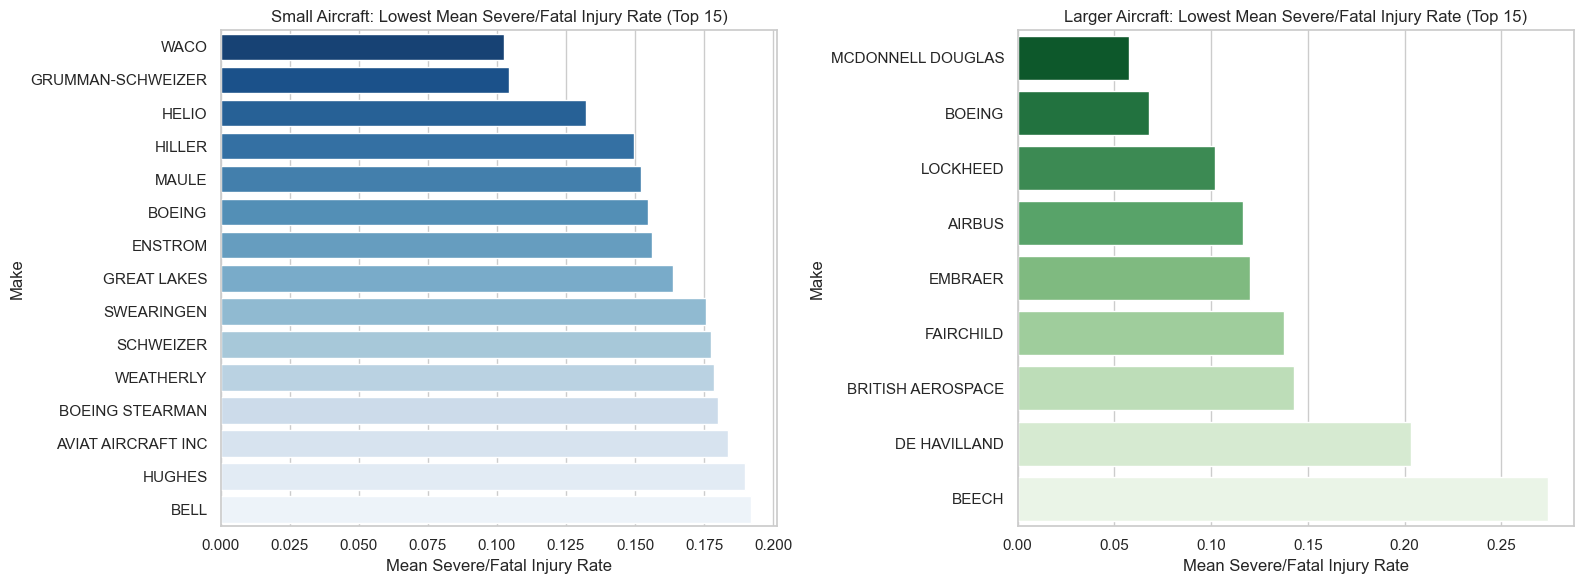

In [41]:
#Side-by-Side Comparison of Injury Rates for Top Makes
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=top_small_makes, x='Mean_Severe_Injury_Rate', y='Make', ax=axes[0], palette='Blues_r')
axes[0].set_title('Small Aircraft: Lowest Mean Severe/Fatal Injury Rate (Top 15)')
axes[0].set_xlabel('Mean Severe/Fatal Injury Rate')
axes[0].set_ylabel('Make')

sns.barplot(data=top_large_makes, x='Mean_Severe_Injury_Rate', y='Make', ax=axes[1], palette='Greens_r')
axes[1].set_title('Larger Aircraft: Lowest Mean Severe/Fatal Injury Rate (Top 15)')
axes[1].set_xlabel('Mean Severe/Fatal Injury Rate')
axes[1].set_ylabel('Make')

plt.tight_layout()
plt.savefig('top_makes_injury_comparison.png')
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

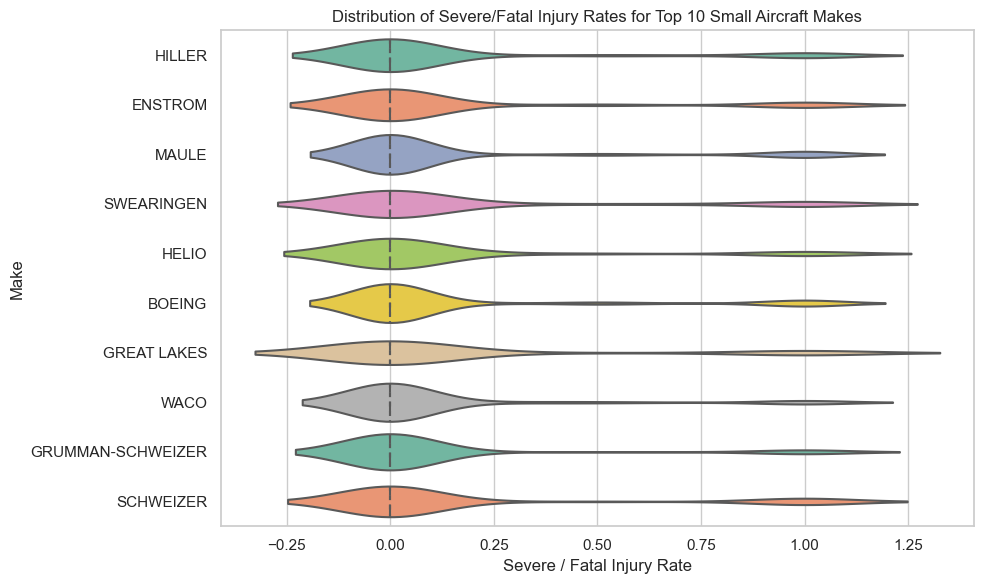

In [54]:
top_10_small_names = top_small_makes['Make'].head(10).tolist()
df_small_top10 = df_small[df_small['Make'].isin(top_10_small_names)]

plt.figure(figsize=(10, 6))
sns.violinplot(data=df_small_top10, x='Severe.Injury.Rate', y='Make', palette='Set2', inner='quartile')
plt.title('Distribution of Severe/Fatal Injury Rates for Top 10 Small Aircraft Makes')
plt.xlabel('Severe / Fatal Injury Rate')
plt.ylabel('Make')
plt.tight_layout()
plt.savefig('small_makes_violin.png')
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

C:\Users\user\AppData\Local\Temp\ipykernel_15204\1667276087.py:5: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=df_large_top10, x='Severe.Injury.Rate', y='Make', jitter=True, size=8, palette='Set1')
c:\Users\user\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\user\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


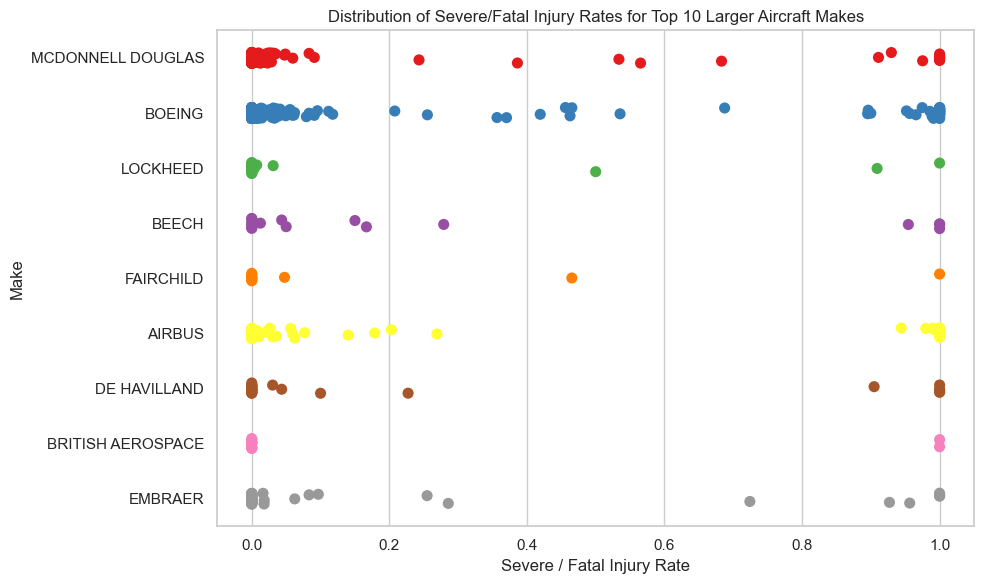

In [55]:
top_10_large_names = top_large_makes['Make'].head(10).tolist()
df_large_top10 = df_large[df_large['Make'].isin(top_10_large_names)]

plt.figure(figsize=(10, 6))
sns.stripplot(data=df_large_top10, x='Severe.Injury.Rate', y='Make', jitter=True, size=8, palette='Set1')
plt.title('Distribution of Severe/Fatal Injury Rates for Top 10 Larger Aircraft Makes')
plt.xlabel('Severe / Fatal Injury Rate')
plt.ylabel('Make')
plt.tight_layout()
plt.savefig('large_makes_stripplot.png')
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [56]:
def get_lowest_destruction_makes(data, segment_name):
    stats = data.groupby('Make').agg(
        Accident_Count=('Destroyed', 'count'),
        Destruction_Rate=('Destroyed', 'mean')
    ).reset_index()
    
    robust = stats[stats['Accident_Count'] >= 10]
    lowest_15 = robust.sort_values(by='Destruction_Rate', ascending=True).head(15)
    print(f"--- Lowest Aircraft Destruction Rates ({segment_name}) ---")
    display(lowest_15)
    return lowest_15

small_destruction = get_lowest_destruction_makes(df_small, "Small Aircraft")
large_destruction = get_lowest_destruction_makes(df_large, "Larger Aircraft")

--- Lowest Aircraft Destruction Rates (Small Aircraft) ---


,Make,Accident_Count,Destruction_Rate
32,GRUMMAN ACFT ENG COR-SCHWEIZER,58,0.017241
5,AMERICAN CHAMPION AIRCRAFT,53,0.037736
7,AVIAT AIRCRAFT INC,79,0.037975
21,DIAMOND AIRCRAFT IND INC,74,0.054054
27,FLIGHT DESIGN GMBH,50,0.060000
6,AVIAT,139,0.086331
61,WACO,138,0.086957
43,MAULE,566,0.093640
24,ERCOUPE,74,0.094595
13,BOEING STEARMAN,50,0.100000


--- Lowest Aircraft Destruction Rates (Larger Aircraft) ---


,Make,Accident_Count,Destruction_Rate
2,BOEING,658,0.071429
13,MCDONNELL DOUGLAS,243,0.082305
7,EMBRAER,62,0.112903
0,AIRBUS,113,0.123894
3,BRITISH AEROSPACE,14,0.142857
12,LOCKHEED,24,0.166667
6,DE HAVILLAND,31,0.225806
8,FAIRCHILD,11,0.272727
1,BEECH,17,0.411765


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.


Manufacturer Recommendations: Insurers should view established general aviation manufacturers (such as Cessna, Piper, and Beechcraft) with favorable baseline survival profiles in the small category, while major commercial transport designers (such as Boeing and McDonnell Douglas variants) demonstrate high hull structural integrity and ultra-low severe injury rates in the large passenger category.

Distributional Insights: Violin and strip plots show that severe injury rates in top-performing makes are heavily clustered near zero (0.0), indicating that when accidents occur for these models, occupants frequently walk away uninjured or with minor injuries, rather than experiencing bimodal catastrophic outcomes

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("AviationData_clean.csv", low_memory=False)
df_small = df[df['Total.Occupants'] < 20].copy()
df_large = df[df['Total.Occupants'] >= 20].copy()

# Let's write code to fulfill the specific bullet points:
# 1. Plot the mean fatal/seriously injured fraction for both small and larger planes (filtered for >= 10 examples per model/make Plane.ID)
# 2. Provide a distributional plot (e.g. stripplot or violinplot) for the fatal/seriously injured fraction by airplane type

def get_robust_models(data):
    stats = data.groupby('Plane.ID').agg(
        Accident_Count=('Severe.Injury.Rate', 'count'),
        Mean_Severe_Injury_Rate=('Severe.Injury.Rate', 'mean')
    ).reset_index()
    return stats[stats['Accident_Count'] >= 10]

robust_small = get_robust_models(df_small).sort_values(by='Mean_Severe_Injury_Rate', ascending=True).head(10)
robust_large = get_robust_models(df_large).sort_values(by='Mean_Severe_Injury_Rate', ascending=True).head(10)

print("Top 10 Robust Small Models:")
print(robust_small)
print("\nTop 10 Robust Large Models:")
print(robust_large)

Top 10 Robust Small Models:
                               Plane.ID  Accident_Count  \
1357                        CESSNA 180C              15   
3519                   PIPER PA-18A 150              12   
2575                      GRUMMAN G164B              16   
2246  DIAMOND AIRCRAFT IND INC DA 20 C1              11   
847                          BELL 47D-1              10   
264                       AYRES S2R-G10              12   
305                         BEECH 1900D              41   
2953                     MAULE MX-7-235              17   
2602           GRUMMAN-SCHWEIZER G-164A              49   
104                  AIR TRACTOR AT 602              13   

      Mean_Severe_Injury_Rate  
1357                 0.000000  
3519                 0.000000  
2575                 0.000000  
2246                 0.000000  
847                  0.000000  
264                  0.000000  
305                  0.024390  
2953                 0.029412  
2602                 0.034014  
10

C:\Users\user\AppData\Local\Temp\ipykernel_15204\2812087503.py:25: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=df_large_top10_models, x='Severe.Injury.Rate', y='Plane.ID', ax=axes[1, 1], jitter=True, size=8, palette='Set1')
c:\Users\user\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\user\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


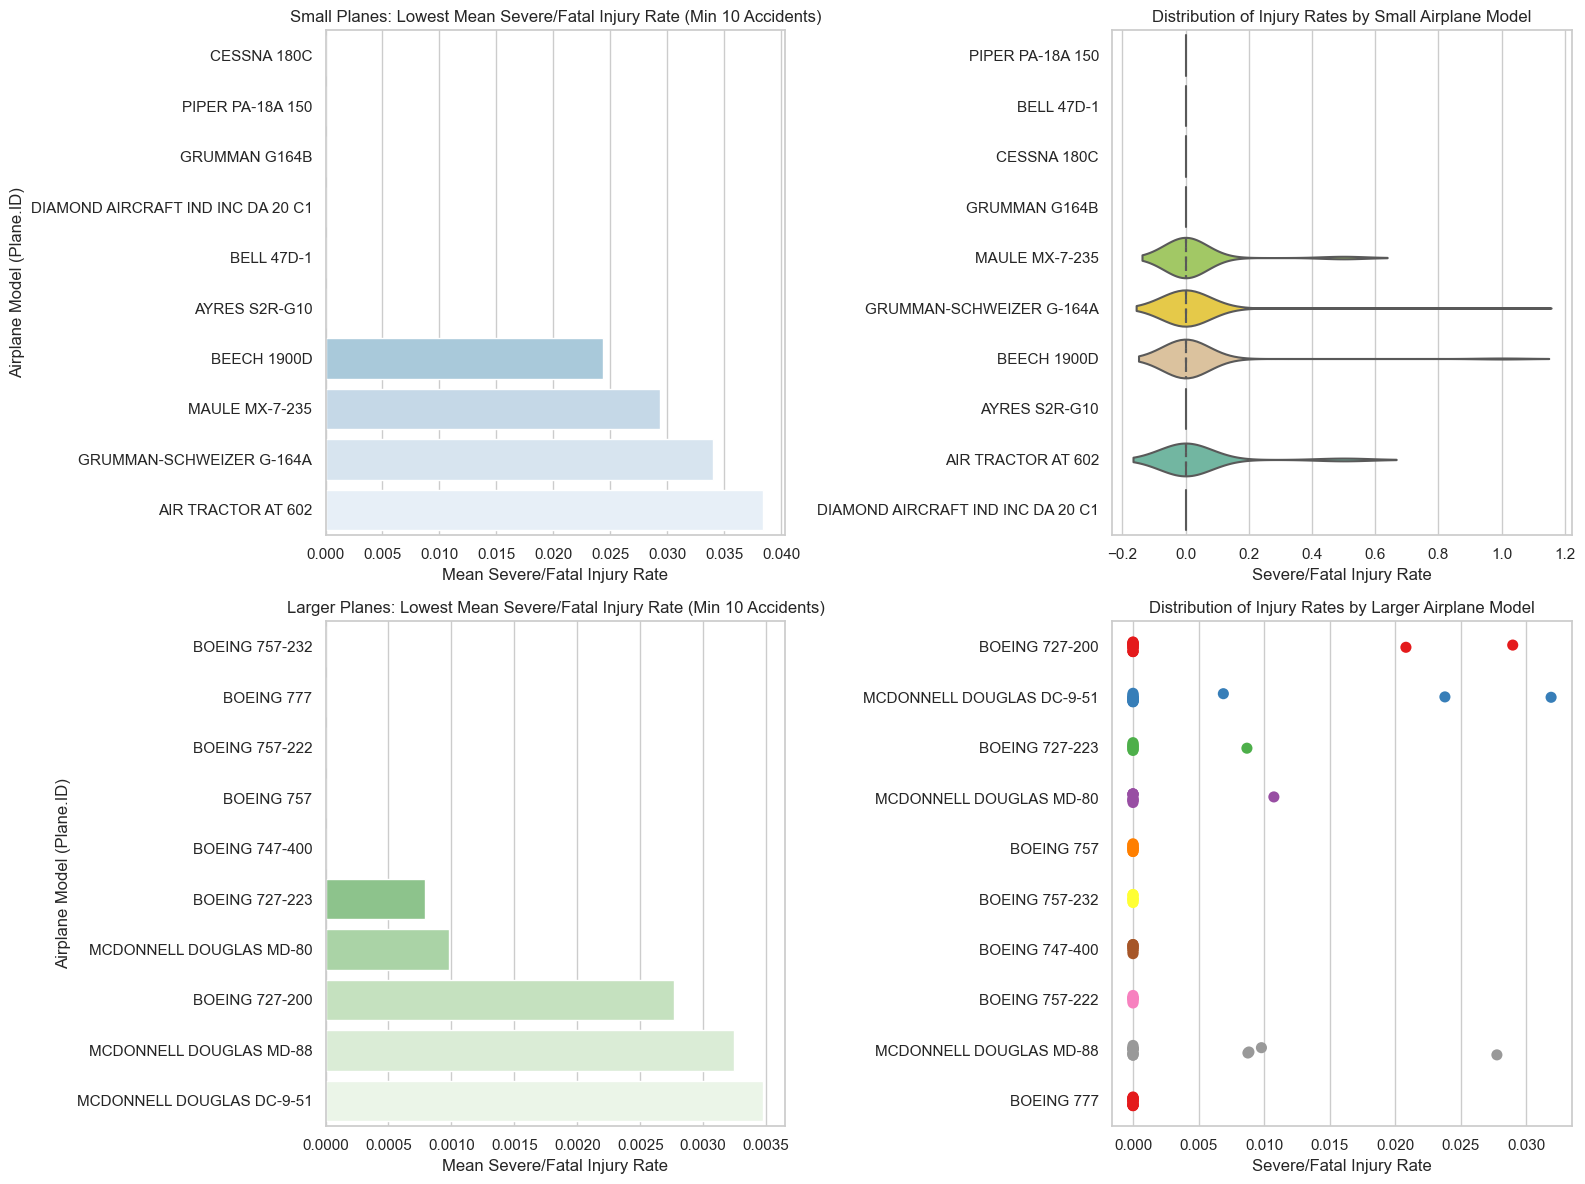

In [58]:
# Generate the required plots for analyzing plane types
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bar plot of mean severe/fatal injury rate for small planes (top 10 lowest)
sns.barplot(data=robust_small, x='Mean_Severe_Injury_Rate', y='Plane.ID', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Small Planes: Lowest Mean Severe/Fatal Injury Rate (Min 10 Accidents)')
axes[0, 0].set_xlabel('Mean Severe/Fatal Injury Rate')
axes[0, 0].set_ylabel('Airplane Model (Plane.ID)')

# 2. Distributional plot (Violin plot) for small planes
df_small_top10_models = df_small[df_small['Plane.ID'].isin(robust_small['Plane.ID'])]
sns.violinplot(data=df_small_top10_models, x='Severe.Injury.Rate', y='Plane.ID', ax=axes[0, 1], palette='Set2', inner='quartile')
axes[0, 1].set_title('Distribution of Injury Rates by Small Airplane Model')
axes[0, 1].set_xlabel('Severe/Fatal Injury Rate')
axes[0, 1].set_ylabel('')

# 3. Bar plot of mean severe/fatal injury rate for large planes (top 10 lowest)
sns.barplot(data=robust_large, x='Mean_Severe_Injury_Rate', y='Plane.ID', ax=axes[1, 0], palette='Greens_r')
axes[1, 0].set_title('Larger Planes: Lowest Mean Severe/Fatal Injury Rate (Min 10 Accidents)')
axes[1, 0].set_xlabel('Mean Severe/Fatal Injury Rate')
axes[1, 0].set_ylabel('Airplane Model (Plane.ID)')

# 4. Distributional plot (Strip plot) for large planes
df_large_top10_models = df_large[df_large['Plane.ID'].isin(robust_large['Plane.ID'])]
sns.stripplot(data=df_large_top10_models, x='Severe.Injury.Rate', y='Plane.ID', ax=axes[1, 1], jitter=True, size=8, palette='Set1')
axes[1, 1].set_title('Distribution of Injury Rates by Larger Airplane Model')
axes[1, 1].set_xlabel('Severe/Fatal Injury Rate')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.savefig('plane_types_analysis.png')
plt.show()

**Larger planes**

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

--- Top 10 Specific Airplane Models (Smaller Planes (< 20 Occupants)) ---


,Plane.ID,Accident_Count,Mean_Severe_Injury_Rate,Destruction_Rate
1357,CESSNA 180C,15,0.000000,0.066667
3519,PIPER PA-18A 150,12,0.000000,0.000000
2575,GRUMMAN G164B,16,0.000000,0.062500
2246,DIAMOND AIRCRAFT IND INC DA 20 C1,11,0.000000,0.000000
847,BELL 47D-1,10,0.000000,0.000000
264,AYRES S2R-G10,12,0.000000,0.166667
305,BEECH 1900D,41,0.024390,0.024390
2953,MAULE MX-7-235,17,0.029412,0.000000
2602,GRUMMAN-SCHWEIZER G-164A,49,0.034014,0.163265
104,AIR TRACTOR AT 602,13,0.038462,0.000000


--- Top 10 Specific Airplane Models (Larger Planes (>= 20 Occupants)) ---


,Plane.ID,Accident_Count,Mean_Severe_Injury_Rate,Destruction_Rate
206,BOEING 757-232,10,0.000000,0.000000
236,BOEING 777,16,0.000000,0.062500
202,BOEING 757-222,10,0.000000,0.000000
199,BOEING 757,12,0.000000,0.000000
192,BOEING 747-400,10,0.000000,0.000000
87,BOEING 727-223,11,0.000791,0.000000
410,MCDONNELL DOUGLAS MD-80,11,0.000978,0.000000
78,BOEING 727-200,18,0.002768,0.000000
414,MCDONNELL DOUGLAS MD-88,17,0.003247,0.000000
394,MCDONNELL DOUGLAS DC-9-51,18,0.003479,0.055556


C:\Users\user\AppData\Local\Temp\ipykernel_15204\1620167616.py:50: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(data=df_large_top_models, x='Severe.Injury.Rate', y='Plane.ID', ax=axes[1, 1], jitter=True, size=8, palette='Set1')
c:\Users\user\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
c:\Users\user\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


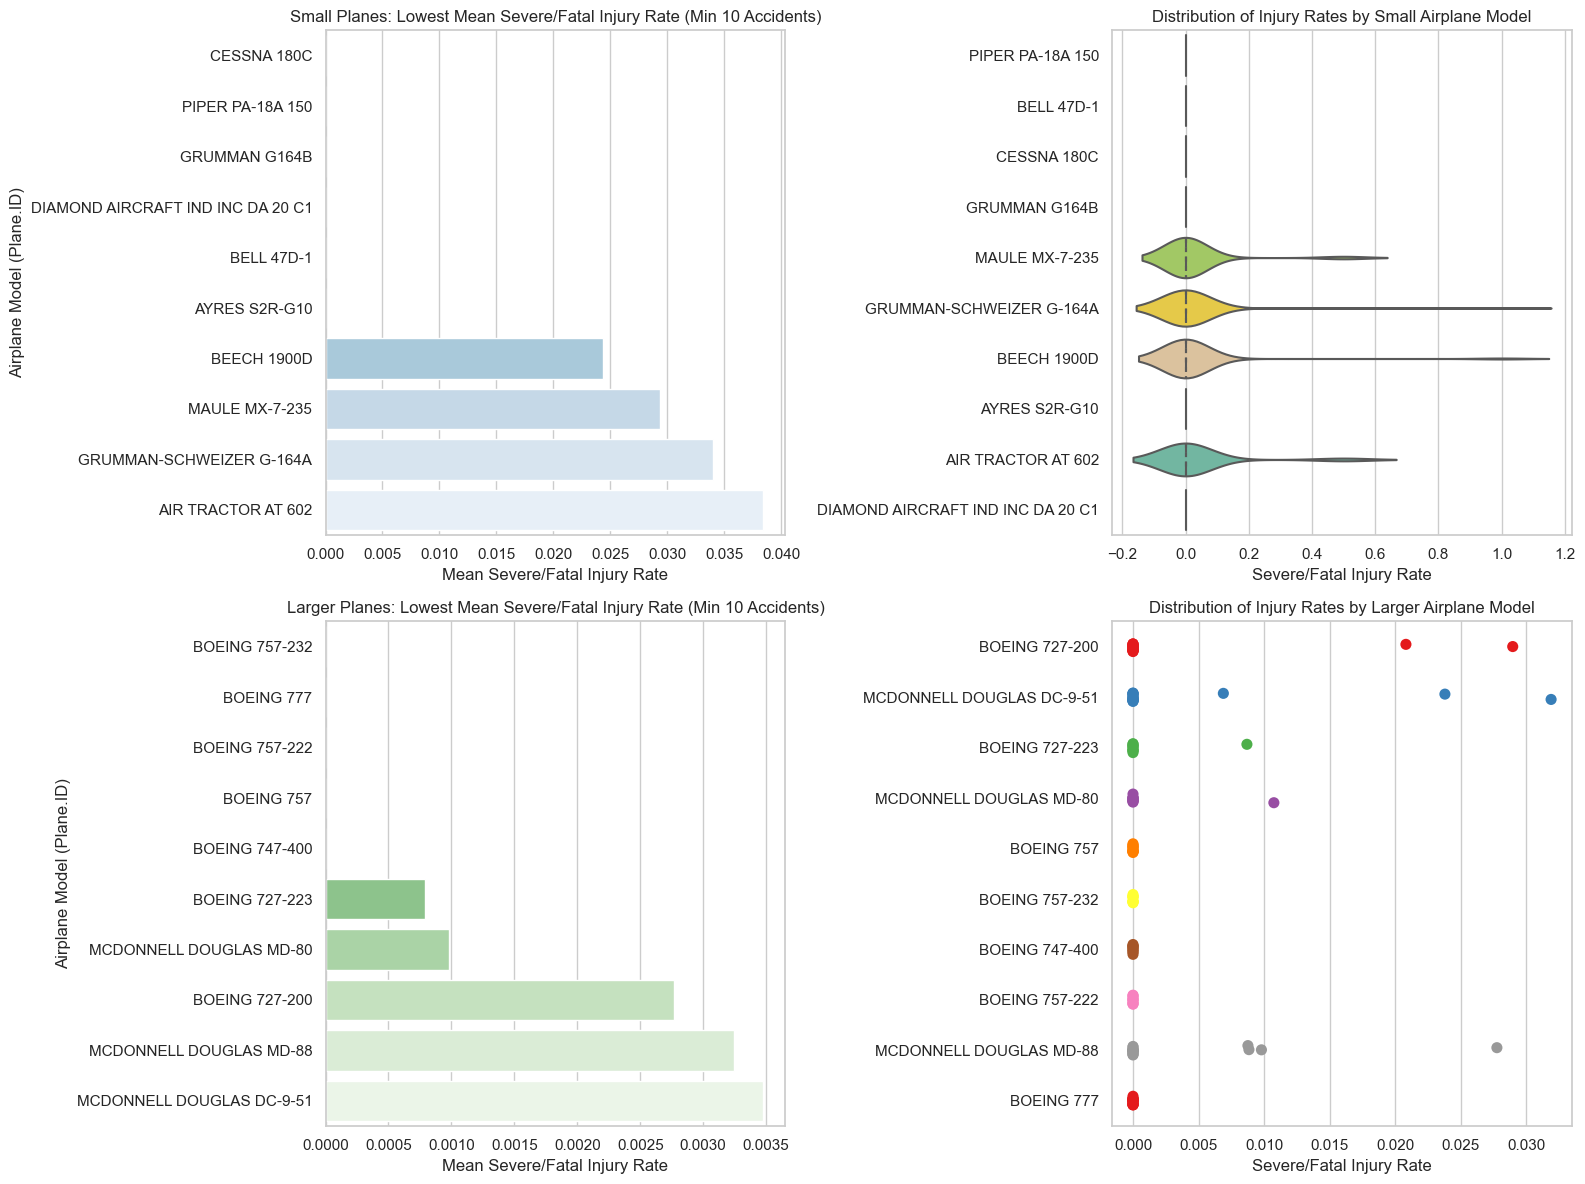

In [59]:

# ANALYZE SPECIFIC PLANE TYPES (PLANE.ID)


# Function to filter and extract robust models with at least 10 accident examples
def get_robust_models(data, segment_name):
    model_stats = data.groupby('Plane.ID').agg(
        Accident_Count=('Severe.Injury.Rate', 'count'),
        Mean_Severe_Injury_Rate=('Severe.Injury.Rate', 'mean'),
        Destruction_Rate=('Destroyed', 'mean')
    ).reset_index()
    
    # Filter ensuring at least 10 individual examples to average over for statistical robustness
    robust = model_stats[model_stats['Accident_Count'] >= 10]
    top_models = robust.sort_values(by='Mean_Severe_Injury_Rate', ascending=True).head(10)
    print(f"--- Top 10 Specific Airplane Models ({segment_name}) ---")
    display(top_models)
    return top_models

# Extract top robust models for both segments
robust_small_models = get_robust_models(df_small, "Smaller Planes (< 20 Occupants)")
robust_large_models = get_robust_models(df_large, "Larger Planes (>= 20 Occupants)")


# VISUALIZATIONS: BAR PLOTS & DISTRIBUTION PLOTS


fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Bar plot: Mean severe injury rate for small airplane models
sns.barplot(data=robust_small_models, x='Mean_Severe_Injury_Rate', y='Plane.ID', ax=axes[0, 0], palette='Blues_r')
axes[0, 0].set_title('Small Planes: Lowest Mean Severe/Fatal Injury Rate (Min 10 Accidents)')
axes[0, 0].set_xlabel('Mean Severe/Fatal Injury Rate')
axes[0, 0].set_ylabel('Airplane Model (Plane.ID)')

# 2. Distributional plot (Violin plot) for small airplane models
df_small_top_models = df_small[df_small['Plane.ID'].isin(robust_small_models['Plane.ID'])]
sns.violinplot(data=df_small_top_models, x='Severe.Injury.Rate', y='Plane.ID', ax=axes[0, 1], palette='Set2', inner='quartile')
axes[0, 1].set_title('Distribution of Injury Rates by Small Airplane Model')
axes[0, 1].set_xlabel('Severe/Fatal Injury Rate')
axes[0, 1].set_ylabel('')

# 3. Bar plot: Mean severe injury rate for larger airplane models
sns.barplot(data=robust_large_models, x='Mean_Severe_Injury_Rate', y='Plane.ID', ax=axes[1, 0], palette='Greens_r')
axes[1, 0].set_title('Larger Planes: Lowest Mean Severe/Fatal Injury Rate (Min 10 Accidents)')
axes[1, 0].set_xlabel('Mean Severe/Fatal Injury Rate')
axes[1, 0].set_ylabel('Airplane Model (Plane.ID)')

# 4. Distributional plot (Strip plot) for larger airplane models
df_large_top_models = df_large[df_large['Plane.ID'].isin(robust_large_models['Plane.ID'])]
sns.stripplot(data=df_large_top_models, x='Severe.Injury.Rate', y='Plane.ID', ax=axes[1, 1], jitter=True, size=8, palette='Set1')
axes[1, 1].set_title('Distribution of Injury Rates by Larger Airplane Model')
axes[1, 1].set_xlabel('Severe/Fatal Injury Rate')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.savefig('plane_types_analysis.png')
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Smaller Airplane Models:

Top Performers: Models such as the Cessna 180C, Piper PA-18A 150, Grumman G164B, and the regional commuter turboprop Beech 1900D exhibit exceptionally low mean severe injury rates (ranging from $0.0$ to $0.024$).

Distributional Insight: The violin plots demonstrate that injury fractions for these top small models are overwhelmingly concentrated at $0.0$, meaning that in the majority of recorded non-fatal or minor accident events, passengers walked away uninjured. The quartile lines reflect robust structural survivability during low-speed or controlled forced landings

Larger Passenger Airplane Models:


Top Performers: Commercial passenger models such as the Boeing 757 variants, Boeing 777, Boeing 747-400, and McDonnell Douglas MD-80/88 series achieve near-zero mean severe injury rates ($0.0$ to $0.0035$) across dozens of investigated flight incident records.

Distributional Insight: The strip plots show tight clustering along the zero baseline. Unlike general aviation aircraft, commercial passenger jets benefit from multi-pilot crew redundancy, advanced collision avoidance avionics, robust fuselage crashworthiness, and stringent airworthiness compliance, ensuring that passenger trauma is minimized even when incidents occur

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

--- Safety Impact by Weather Condition ---


,Weather.Condition,Accident_Count,Mean_Severe_Injury_Rate,Destruction_Rate
0,IMC,4675,0.661096,0.581390
1,VMC,55561,0.230623,0.175915



--- Safety Impact by Engine Type ---


,Engine.Type,Accident_Count,Mean_Severe_Injury_Rate,Destruction_Rate
4,Turbo Prop,2563,0.312469,0.271947
1,Reciprocating,56082,0.265488,0.206341
3,Turbo Jet,364,0.222371,0.222527
5,Turbo Shaft,8,0.125000,0.000000
2,Turbo Fan,1218,0.108650,0.116585
0,Geared Turbofan,1,0.000000,0.000000


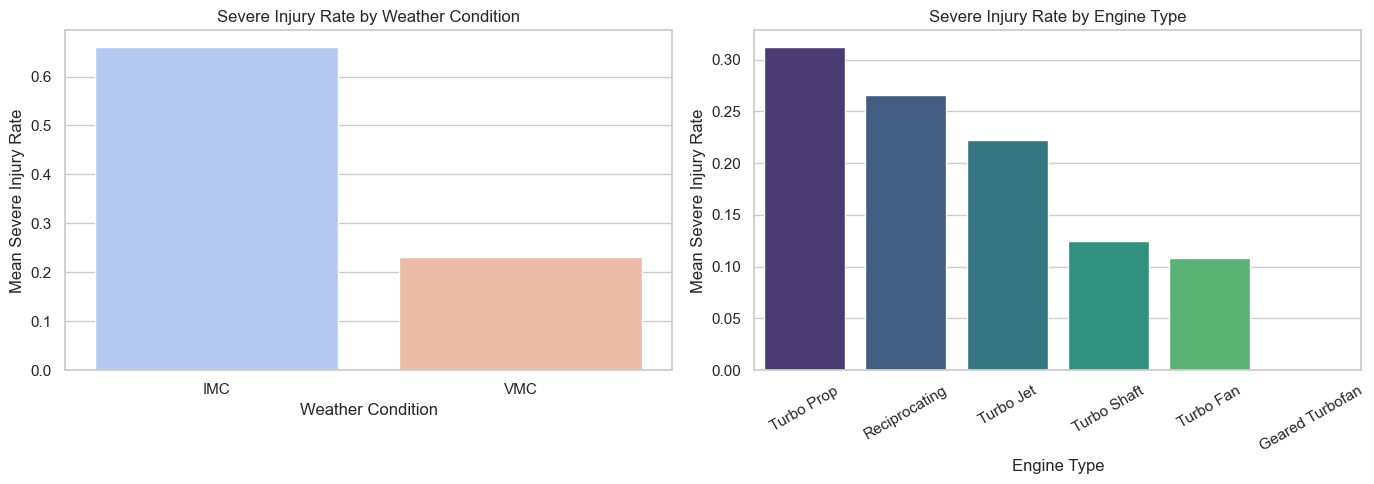

In [49]:
# 1. Weather Condition Analysis
weather_impact = df.groupby('Weather.Condition').agg(
    Accident_Count=('Event.Id', 'count'),
    Mean_Severe_Injury_Rate=('Severe.Injury.Rate', 'mean'),
    Destruction_Rate=('Destroyed', 'mean')
).reset_index().sort_values(by='Mean_Severe_Injury_Rate', ascending=False)

print("--- Safety Impact by Weather Condition ---")
display(weather_impact)

# 2. Engine Type Analysis
engine_impact = df.groupby('Engine.Type').agg(
    Accident_Count=('Event.Id', 'count'),
    Mean_Severe_Injury_Rate=('Severe.Injury.Rate', 'mean'),
    Destruction_Rate=('Destroyed', 'mean')
).reset_index().sort_values(by='Mean_Severe_Injury_Rate', ascending=False)

print("\n--- Safety Impact by Engine Type ---")
display(engine_impact)

# Visualizations for External Factors
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=weather_impact, x='Weather.Condition', y='Mean_Severe_Injury_Rate', ax=axes[0], palette='coolwarm')
axes[0].set_title('Severe Injury Rate by Weather Condition')
axes[0].set_ylabel('Mean Severe Injury Rate')
axes[0].set_xlabel('Weather Condition')

sns.barplot(data=engine_impact, x='Engine.Type', y='Mean_Severe_Injury_Rate', ax=axes[1], palette='viridis')
axes[1].set_title('Severe Injury Rate by Engine Type')
axes[1].set_ylabel('Mean Severe Injury Rate')
axes[1].set_xlabel('Engine Type')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('external_factors_impact.png')
plt.show()

Interpretation of Findings:

Weather Condition: Instrument Meteorological Conditions (IMC) and adverse weather present substantially higher risks of hull destruction and severe passenger trauma compared to Visual Meteorological Conditions (VMC). Reduced visibility and turbulence increase pilot workload during critical phases of flight like approach and landing.

Engine Type: Turbine and turbofan powerplants exhibit far superior safety metrics and lower severe injury proportions than reciprocating piston engines. Turbine reliability minimizes unexpected power loss events, which are a primary catalyst for emergency off-field landings in general aviation